## Inflation forecastin


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

PROJECT_ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / 'modelling').is_dir() and (p / 'data').is_dir()
)
RESULTS = PROJECT_ROOT / 'data' / 'processed' / 'model_results'
BASELINE = RESULTS / 'baseline'
MACRO = RESULTS / 'macro'
AR_SENTIMENT_AGGREGATIONS = RESULTS / 'ar_sentiment_aggregations'
ARHMM_SENTIMENT_AGGREGATIONS = RESULTS / 'arhmm_sentiment_aggregations'

forecasts = pd.read_csv(BASELINE / 'forecasts.csv', parse_dates=['Date'])
metrics = pd.read_csv(BASELINE / 'metrics.csv')
baseline_parameters = json.loads((BASELINE / 'parameters.json').read_text(encoding='utf-8'))['models']
macro_forecasts = pd.read_csv(MACRO / 'forecasts.csv', parse_dates=['Date'])
macro_metrics = pd.read_csv(MACRO / 'metrics.csv').sort_values('rmse').reset_index(drop=True)
macro_details = json.loads((MACRO / 'parameters.json').read_text(encoding='utf-8'))
ar_sentiment_aggregation_metrics = pd.read_csv(AR_SENTIMENT_AGGREGATIONS / 'metrics.csv')
arhmm_sentiment_aggregation_metrics = pd.read_csv(ARHMM_SENTIMENT_AGGREGATIONS / 'metrics.csv')
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})


**Existing models**


,model,rmse,mae,mean_error_actual_minus_forecast
0,AR(1),0.2652,0.1956,0.0675
1,ARX + sentiment,0.2656,0.1963,0.0669
2,AR-HMM,0.2695,0.1961,0.0744
3,LASSO inflation + sentiment,0.2863,0.2069,0.1038
4,LASSO inflation only,0.2915,0.2099,0.1093
5,AR-HMM + sentiment,0.3008,0.2137,0.0887
6,HMM,0.3306,0.2345,0.1264


Common period: 2017-01 to 2023-12; 84 months


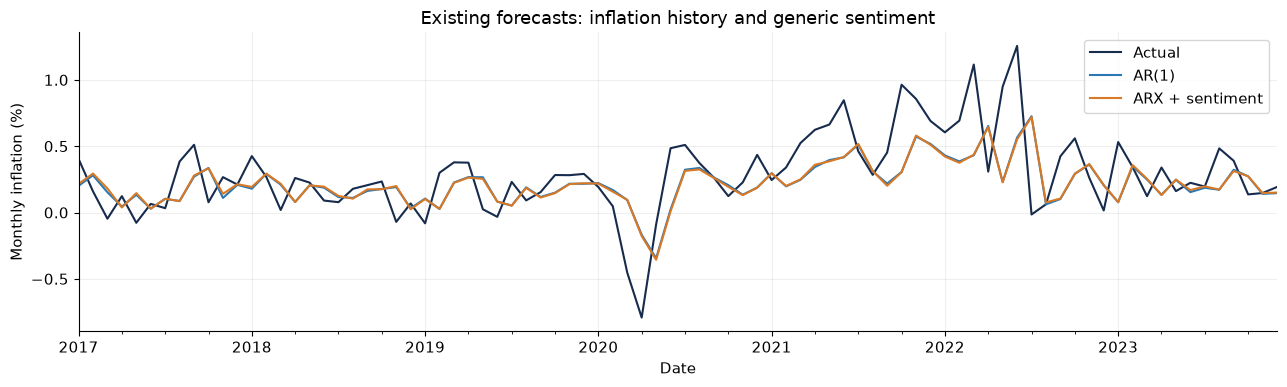

In [2]:
display(metrics.round(4))
print(f"Common period: {forecasts['Date'].min():%Y-%m} to {forecasts['Date'].max():%Y-%m}; {len(forecasts)} months")
ax = forecasts.set_index('Date')[['Actual', 'AR(1)', 'ARX + sentiment']].plot(
    figsize=(13, 4), color=['#172b4d', '#2878b5', '#d97925'],
    title='Existing forecasts: inflation history and generic sentiment', ylabel='Monthly inflation (%)',
)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


**Existing regime models**

,model,rmse,mae,mean_error_actual_minus_forecast
2,AR-HMM,0.2695,0.1961,0.0744
5,AR-HMM + sentiment,0.3008,0.2137,0.0887
6,HMM,0.3306,0.2345,0.1264


,HMM state mean
0,0.183178
1,-1.130828


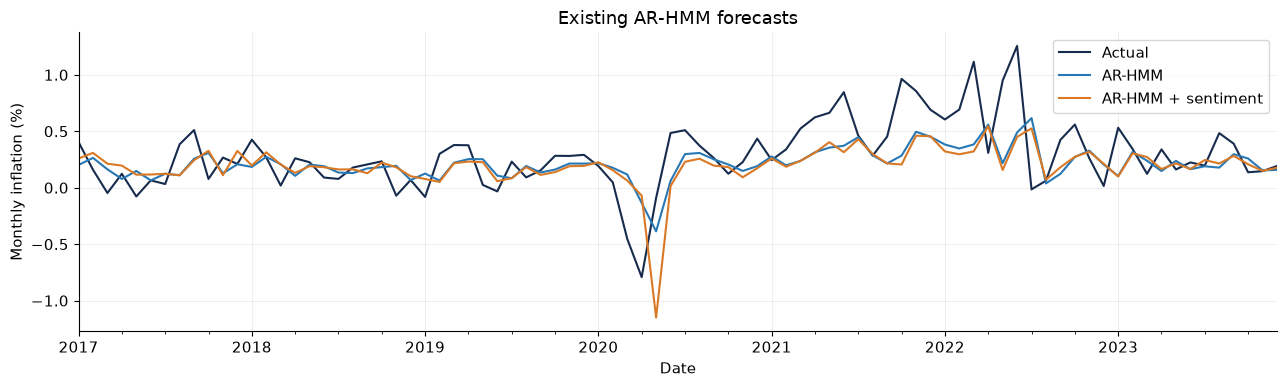

In [3]:
display(metrics.loc[metrics['model'].isin(['HMM', 'AR-HMM', 'AR-HMM + sentiment'])].round(4))
display(pd.DataFrame({'HMM state mean': baseline_parameters['HMM']['state_means']}))
ax = forecasts.set_index('Date')[['Actual', 'AR-HMM', 'AR-HMM + sentiment']].plot(
    figsize=(13, 4), title='Existing AR-HMM forecasts', ylabel='Monthly inflation (%)',
    color=['#172b4d', '#2878b5', '#d97925'],
)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


**Macroeconomic indicators**


,model,macro_count,rmse,mae,mean_error_actual_minus_forecast,rmse_improvement_pct
0,Inflation + Oil + Unemployment,2,0.2617,0.1958,0.0703,0.9069
1,Inflation + Oil + Unemployment + Industry,3,0.2627,0.1968,0.0710,0.5187
2,Inflation only (lag 1),0,0.2641,0.1950,0.0535,0.0000
3,Inflation + Fed rate,1,0.2649,0.1983,0.0421,-0.3169
4,Inflation + Oil + Unemployment + Fed rate,3,0.2649,0.2015,0.0540,-0.3214
5,Inflation + Oil + Unemployment + Industry + Fe...,4,0.2654,0.2030,0.0541,-0.4808
6,Inflation + Oil + Industry + Fed rate,3,0.2674,0.2010,0.0633,-1.2594
7,Inflation + Oil + Industry,2,0.2679,0.2001,0.0760,-1.4506
8,Inflation + Unemployment,1,0.2682,0.1967,0.0522,-1.5646
9,Inflation + Oil,1,0.2689,0.1946,0.0750,-1.8333


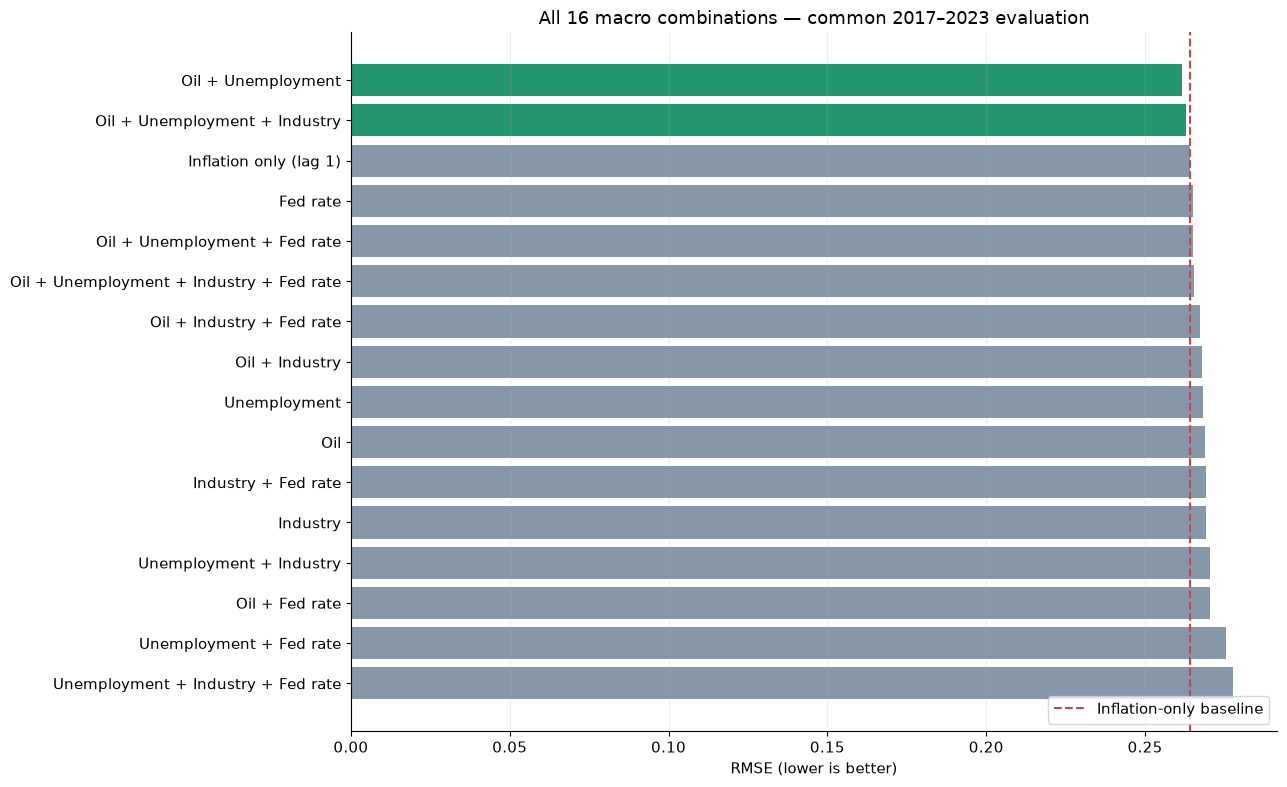

In [4]:
columns = ['model', 'macro_count', 'rmse', 'mae', 'mean_error_actual_minus_forecast', 'rmse_improvement_pct']
display(macro_metrics[columns].round(4))
plot_data = macro_metrics.sort_values('rmse', ascending=False)
colors = ['#23956f' if x > 0 else '#8697aa' for x in plot_data['rmse_improvement_pct']]
fig, ax = plt.subplots(figsize=(13, 8))
ax.barh(plot_data['model'].str.replace('Inflation + ', '', regex=False), plot_data['rmse'], color=colors)
base_name = 'Inflation only (lag 1)'
base_rmse = float(macro_metrics.loc[macro_metrics['model'].eq(base_name), 'rmse'].iloc[0])
ax.axvline(base_rmse, color='#c64747', linestyle='--', label='Inflation-only baseline')
ax.set(xlabel='RMSE (lower is better)', title='All 16 macro combinations — common 2017–2023 evaluation')
ax.legend(loc='lower right')
ax.grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.show()


,model,macro_count,rmse,mae,mean_error_actual_minus_forecast,rmse_improvement_pct
0,AR-HMM + Oil + Industry,2,0.2700,0.2036,0.0745,2.3946
1,AR-HMM + Fed rate,1,0.2716,0.1921,0.0422,1.7876
2,AR-HMM + Oil + Unemployment,2,0.2731,0.2078,0.0762,1.2520
3,AR-HMM inflation only (lag 1),0,0.2766,0.2026,0.0654,0.0000
4,AR-HMM + Oil + Unemployment + Industry,3,0.2780,0.2121,0.0756,-0.5068
5,AR-HMM + Oil,1,0.2785,0.2041,0.0858,-0.7012
6,AR-HMM + Oil + Unemployment + Fed rate,3,0.2812,0.2106,0.0791,-1.6811
7,AR-HMM + Unemployment + Industry,2,0.2833,0.2035,0.0336,-2.4329
8,AR-HMM + Oil + Unemployment + Industry + Fed rate,4,0.2869,0.2178,0.0771,-3.7341
9,AR-HMM + Industry,1,0.2888,0.2044,0.0259,-4.4127


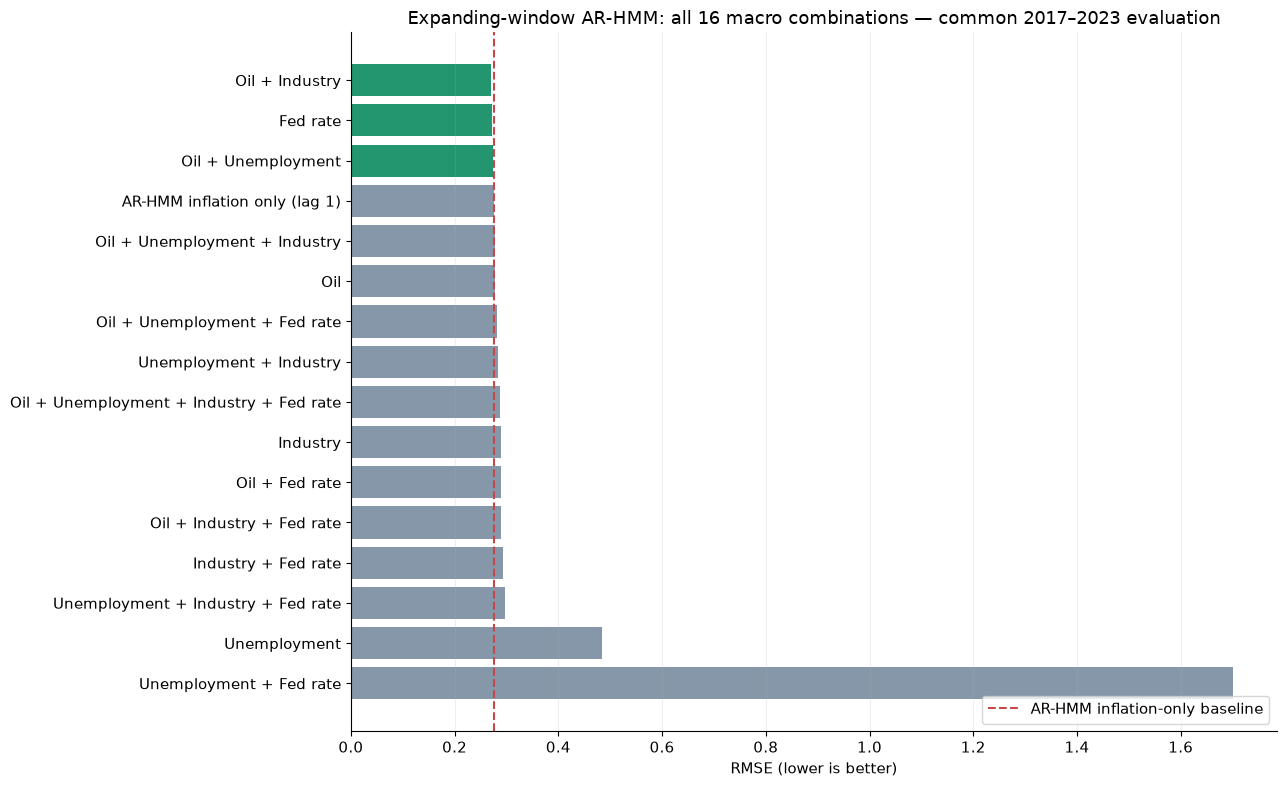

In [5]:
ARHMM_MACRO = RESULTS / 'arhmm_macro'
ARHMM_SENTIMENT = RESULTS / 'arhmm_sentiment'
arhmm_macro_forecasts = pd.read_csv(ARHMM_MACRO / 'forecasts.csv', parse_dates=['Date'])
arhmm_macro_metrics = pd.read_csv(ARHMM_MACRO / 'metrics.csv').sort_values('rmse').reset_index(drop=True)
arhmm_macro_details = json.loads((ARHMM_MACRO / 'parameters.json').read_text(encoding='utf-8'))
arhmm_base_name = 'AR-HMM inflation only (lag 1)'
arhmm_base_rmse = float(arhmm_macro_metrics.loc[
    arhmm_macro_metrics['model'].eq(arhmm_base_name), 'rmse'
].iloc[0])
arhmm_columns = ['model', 'macro_count', 'rmse', 'mae', 'mean_error_actual_minus_forecast', 'rmse_improvement_pct']
display(arhmm_macro_metrics[arhmm_columns].round(4))

arhmm_plot_data = arhmm_macro_metrics.sort_values('rmse', ascending=False)
arhmm_colors = ['#23956f' if x > 0 else '#8697aa' for x in arhmm_plot_data['rmse_improvement_pct']]
fig, ax = plt.subplots(figsize=(13, 8))
ax.barh(
    arhmm_plot_data['model'].str.replace('AR-HMM + ', '', regex=False),
    arhmm_plot_data['rmse'], color=arhmm_colors,
)
ax.axvline(arhmm_base_rmse, color='#c64747', linestyle='--', label='AR-HMM inflation-only baseline')
ax.set(xlabel='RMSE (lower is better)', title='Expanding-window AR-HMM: all 16 macro combinations — common 2017–2023 evaluation')
ax.legend(loc='lower right')
ax.grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.show()


**AR(1)**

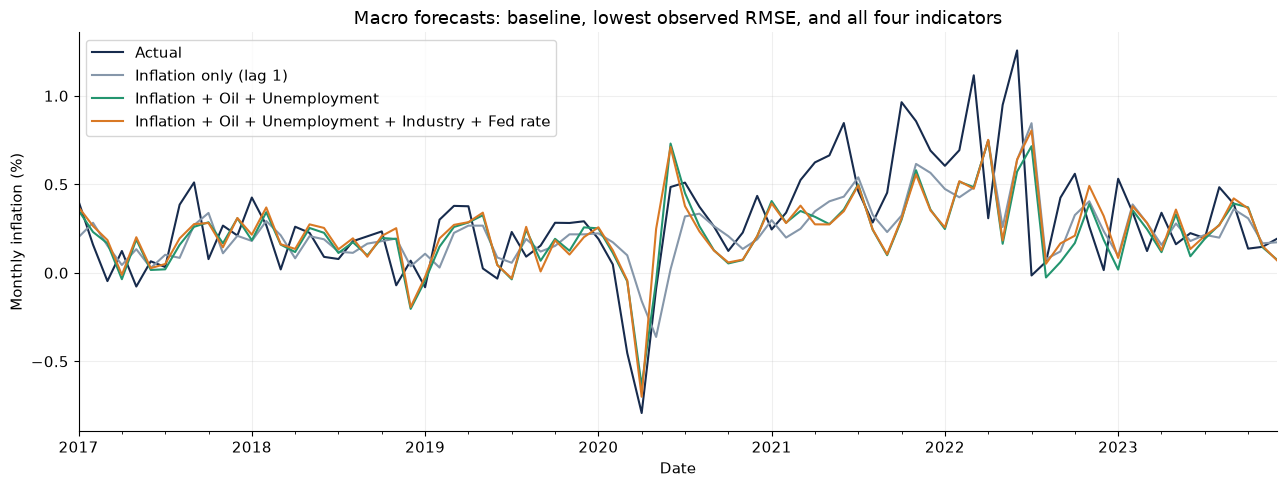

In [6]:
best = macro_metrics.iloc[0]
full_name = 'Inflation + Oil + Unemployment + Industry + Fed rate'
full = macro_metrics.loc[macro_metrics['model'].eq(full_name)].iloc[0]
ax = macro_forecasts.set_index('Date')[list(dict.fromkeys(['Actual', base_name, best['model'], full_name]))].plot(
    figsize=(13, 5), ylabel='Monthly inflation (%)',
    title='Macro forecasts: baseline, lowest observed RMSE, and all four indicators',
    color=['#172b4d', '#8697aa', '#23956f', '#d97925'],
)
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()


**AR-HMM (expanding window)**

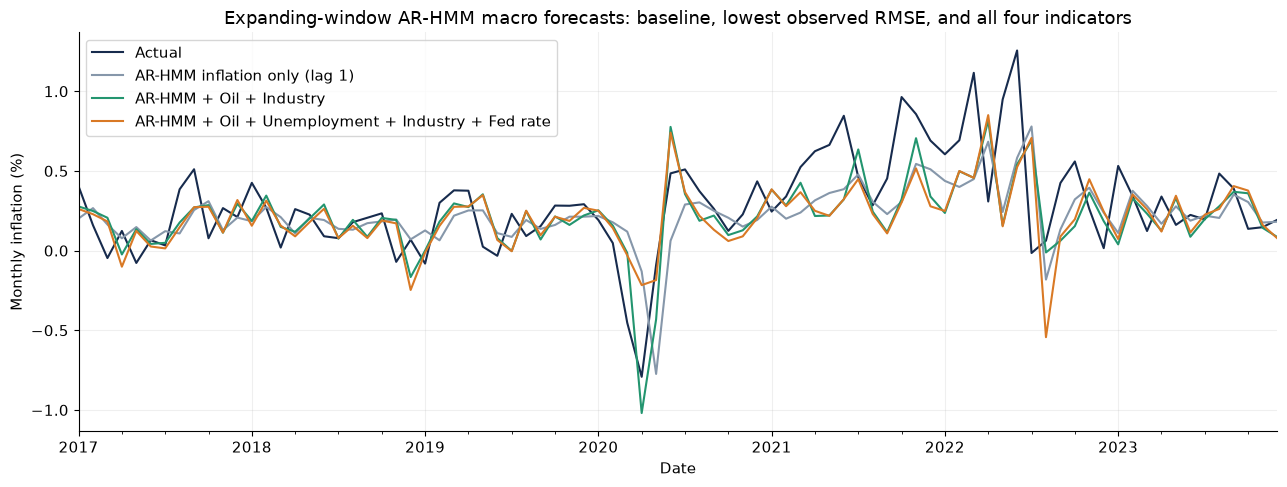

In [7]:
arhmm_best = arhmm_macro_metrics.loc[arhmm_macro_metrics['macro_count'].gt(0)].iloc[0]
arhmm_full_name = 'AR-HMM + Oil + Unemployment + Industry + Fed rate'
arhmm_selected_names = list(dict.fromkeys([arhmm_base_name, arhmm_best['model'], arhmm_full_name]))
ax = arhmm_macro_forecasts.set_index('Date')[['Actual', *arhmm_selected_names]].plot(
    figsize=(13, 5), ylabel='Monthly inflation (%)',
    title='Expanding-window AR-HMM macro forecasts: baseline, lowest observed RMSE, and all four indicators',
    color=['#172b4d', '#8697aa', '#23956f', '#d97925'][:1 + len(arhmm_selected_names)],
)
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()


**Sentiment AR(1)**

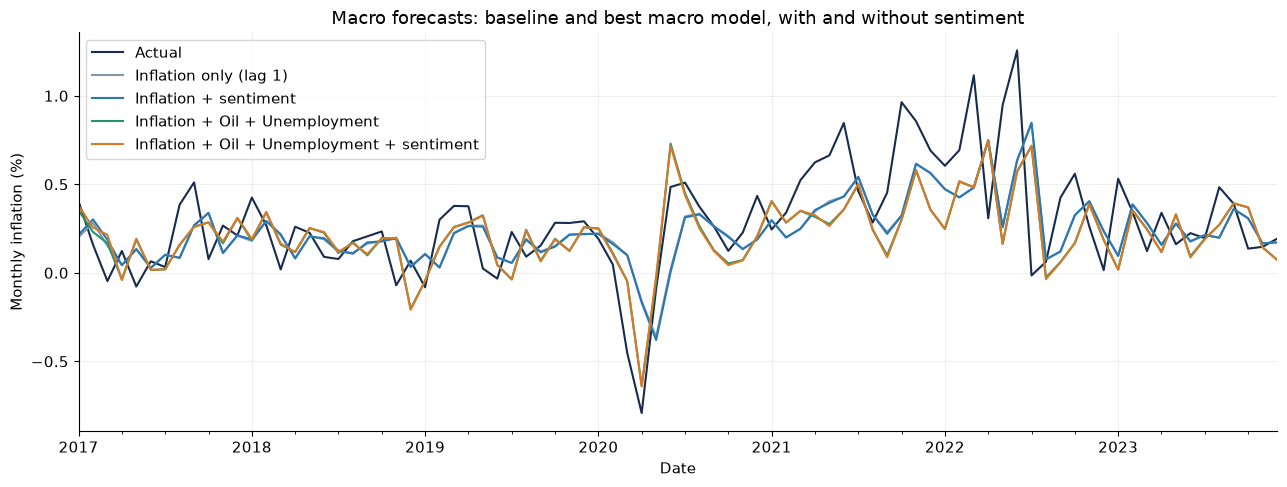

In [8]:
import sys
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import importlib
for module_name in (
    'modelling.data_pipeline', 'modelling.evaluation',
    'modelling.models', 'modelling.run_experiments',
):
    importlib.reload(importlib.import_module(module_name))
from modelling.run_experiments import run_sentiment_comparison

sentiment_forecasts, sentiment_metrics, best_macro_name = run_sentiment_comparison(
    PROJECT_ROOT / 'data' / 'processed' / 'modelling_datasets' / 'us_nyt_monthly_experiment.csv',
    macro_dir=MACRO,
)
ax = sentiment_forecasts.set_index('Date')[[
    'Actual', 'Inflation only (lag 1)', 'Inflation + sentiment',
    best_macro_name, best_macro_name + ' + sentiment',
]].plot(
    figsize=(13, 5), ylabel='Monthly inflation (%)',
    title='Macro forecasts: baseline and best macro model, with and without sentiment',
    color=['#172b4d', '#8697aa', '#2878b5', '#23956f', '#d97925'],
)
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()


**Sentiment AR-HMM (expanding window)**

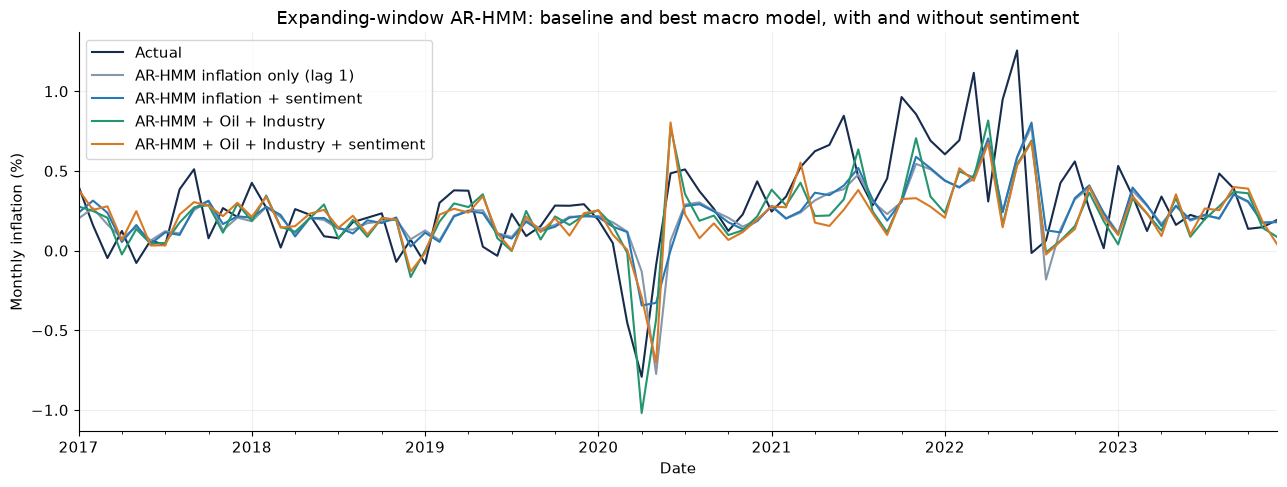

In [9]:
arhmm_sentiment_forecasts = pd.read_csv(ARHMM_SENTIMENT / 'forecasts.csv', parse_dates=['Date'])
arhmm_sentiment_metrics = pd.read_csv(ARHMM_SENTIMENT / 'metrics.csv').sort_values('rmse').reset_index(drop=True)
arhmm_sentiment_details = json.loads((ARHMM_SENTIMENT / 'parameters.json').read_text(encoding='utf-8'))
arhmm_best_macro_name = arhmm_sentiment_details['metadata']['best_macro_model']
arhmm_sentiment_name = 'AR-HMM inflation + sentiment'
arhmm_best_sentiment_name = arhmm_best_macro_name + ' + sentiment'

ax = arhmm_sentiment_forecasts.set_index('Date')[[
    'Actual', arhmm_base_name, arhmm_sentiment_name,
    arhmm_best_macro_name, arhmm_best_sentiment_name,
]].plot(
    figsize=(13, 5), ylabel='Monthly inflation (%)',
    title='Expanding-window AR-HMM: baseline and best macro model, with and without sentiment',
    color=['#172b4d', '#8697aa', '#2878b5', '#23956f', '#d97925'],
)
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()


**AR(1) Error**

,model,rmse
0,Inflation + Oil + Unemployment,0.2617
1,Inflation + Oil + Unemployment + sentiment,0.2630
2,Inflation only (lag 1),0.2641
3,Inflation + sentiment,0.2652


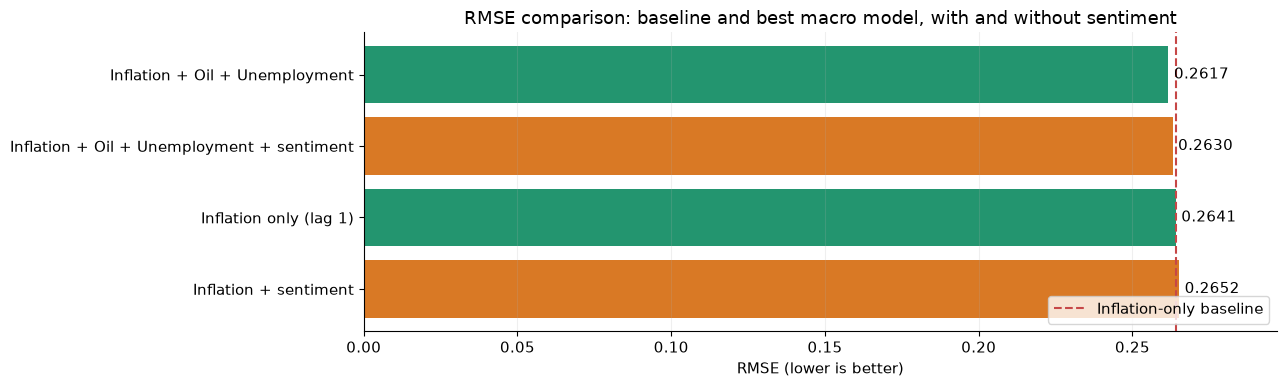

In [10]:
rmse_comparison = sentiment_metrics[['model', 'rmse']].sort_values('rmse').reset_index(drop=True)
display(rmse_comparison.round(4))

plot_data = rmse_comparison.sort_values('rmse', ascending=False)
fig, ax = plt.subplots(figsize=(13, 4))
bars = ax.barh(
    plot_data['model'], plot_data['rmse'],
    color=['#d97925' if 'sentiment' in model else '#23956f' for model in plot_data['model']],
)
reference_rmse = float(rmse_comparison.loc[
    rmse_comparison['model'].eq('Inflation only (lag 1)'), 'rmse'
].iloc[0])
ax.axvline(reference_rmse, color='#c64747', linestyle='--', label='Inflation-only baseline')
ax.bar_label(bars, fmt='%.4f', padding=4)
ax.set(xlabel='RMSE (lower is better)', title='RMSE comparison: baseline and best macro model, with and without sentiment')
ax.set_xlim(0, float(plot_data['rmse'].max()) * 1.12)
ax.grid(axis='x', alpha=0.2)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()


**AR-HMM Error (expanding window)**

,model,rmse
0,AR-HMM inflation + sentiment,0.2633
1,AR-HMM + Oil + Industry,0.2700
2,AR-HMM inflation only (lag 1),0.2766
3,AR-HMM + Oil + Industry + sentiment,0.2913


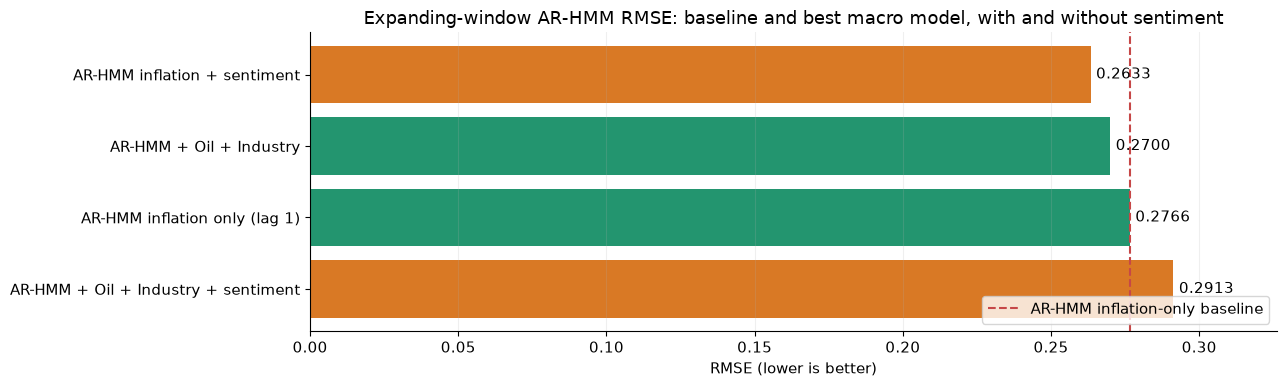

In [11]:
arhmm_rmse_comparison = arhmm_sentiment_metrics[['model', 'rmse']].sort_values('rmse').reset_index(drop=True)
display(arhmm_rmse_comparison.round(4))

arhmm_sentiment_plot_data = arhmm_rmse_comparison.sort_values('rmse', ascending=False)
fig, ax = plt.subplots(figsize=(13, 4))
bars = ax.barh(
    arhmm_sentiment_plot_data['model'], arhmm_sentiment_plot_data['rmse'],
    color=['#d97925' if 'sentiment' in model else '#23956f' for model in arhmm_sentiment_plot_data['model']],
)
arhmm_reference_rmse = float(arhmm_rmse_comparison.loc[
    arhmm_rmse_comparison['model'].eq(arhmm_base_name), 'rmse'
].iloc[0])
ax.axvline(arhmm_reference_rmse, color='#c64747', linestyle='--', label='AR-HMM inflation-only baseline')
ax.bar_label(bars, fmt='%.4f', padding=4)
ax.set(xlabel='RMSE (lower is better)', title='Expanding-window AR-HMM RMSE: baseline and best macro model, with and without sentiment')
ax.set_xlim(0, float(arhmm_sentiment_plot_data['rmse'].max()) * 1.12)
ax.grid(axis='x', alpha=0.2)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()


,family,specification,model,rmse,mae,mean_error_actual_minus_forecast
0,AR(1),Baseline,Inflation only (lag 1),0.2641,0.1950,0.0535
1,AR(1),Baseline + sentiment,Inflation + sentiment,0.2652,0.1962,0.0538
2,AR(1),Best macro,Inflation + Oil + Unemployment,0.2617,0.1958,0.0703
3,AR(1),Best macro + sentiment,Inflation + Oil + Unemployment + sentiment,0.2630,0.1976,0.0697
4,AR-HMM,Baseline,AR-HMM inflation only (lag 1),0.2766,0.2026,0.0654
5,AR-HMM,Baseline + sentiment,AR-HMM inflation + sentiment,0.2633,0.1965,0.0576
6,AR-HMM,Best macro,AR-HMM + Oil + Industry,0.2700,0.2036,0.0745
7,AR-HMM,Best macro + sentiment,AR-HMM + Oil + Industry + sentiment,0.2913,0.2173,0.0759


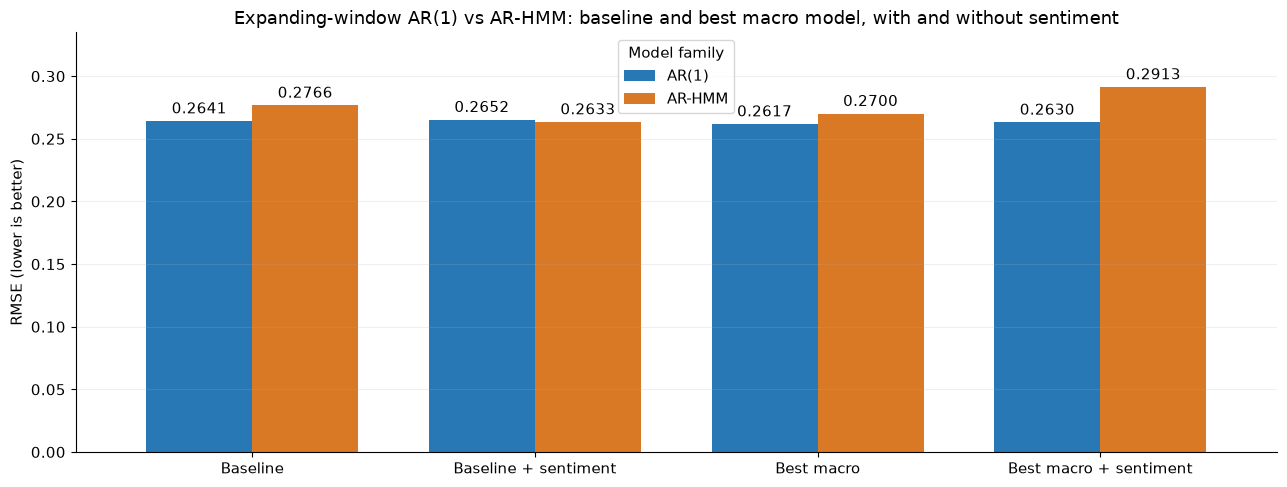

In [12]:
comparison_models = [
    ('Baseline', 'AR(1)', 'Inflation only (lag 1)', sentiment_metrics),
    ('Baseline + sentiment', 'AR(1)', 'Inflation + sentiment', sentiment_metrics),
    ('Best macro', 'AR(1)', best_macro_name, sentiment_metrics),
    ('Best macro + sentiment', 'AR(1)', best_macro_name + ' + sentiment', sentiment_metrics),
    ('Baseline', 'AR-HMM', arhmm_base_name, arhmm_sentiment_metrics),
    ('Baseline + sentiment', 'AR-HMM', arhmm_sentiment_name, arhmm_sentiment_metrics),
    ('Best macro', 'AR-HMM', arhmm_best_macro_name, arhmm_sentiment_metrics),
    ('Best macro + sentiment', 'AR-HMM', arhmm_best_sentiment_name, arhmm_sentiment_metrics),
]

comparison_rows = []
for specification, family, model_name, metric_table in comparison_models:
    row = metric_table.loc[metric_table['model'].eq(model_name)].iloc[0]
    comparison_rows.append({
        'family': family,
        'specification': specification,
        'model': model_name,
        'rmse': row['rmse'],
        'mae': row['mae'],
        'mean_error_actual_minus_forecast': row['mean_error_actual_minus_forecast'],
    })

ar1_arhmm_comparison = pd.DataFrame(comparison_rows)
display(ar1_arhmm_comparison.round(4))

specification_order = ['Baseline', 'Baseline + sentiment', 'Best macro', 'Best macro + sentiment']
rmse_by_family = (
    ar1_arhmm_comparison.pivot(index='specification', columns='family', values='rmse')
    .reindex(index=specification_order, columns=['AR(1)', 'AR-HMM'])
)
ax = rmse_by_family.plot.bar(
    figsize=(13, 5), color=['#2878b5', '#d97925'], width=0.75,
    ylabel='RMSE (lower is better)',
    title='Expanding-window AR(1) vs AR-HMM: baseline and best macro model, with and without sentiment',
)
for container in ax.containers:
    ax.bar_label(container, fmt='%.4f', padding=3)
ax.set_xlabel('')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.set_ylim(0, float(rmse_by_family.max().max()) * 1.15)
ax.grid(axis='y', alpha=0.2)
ax.legend(title='Model family')
plt.tight_layout()
plt.show()


**Alternative FinBERT aggregation comparison**


In [13]:
aggregation_columns = [
    'model', 'rmse', 'mae',
    'mean_error_actual_minus_forecast', 'rmse_improvement_pct',
]
display(Markdown('**AR results**'))
display(ar_sentiment_aggregation_metrics[aggregation_columns].sort_values('rmse').round(4))
display(Markdown('**AR-HMM results**'))
display(arhmm_sentiment_aggregation_metrics[aggregation_columns].sort_values('rmse').round(4))


**AR results**

,model,rmse,mae,mean_error_actual_minus_forecast,rmse_improvement_pct
0,Inflation + sentiment dispersion,0.2626,0.1959,0.0478,0.5755
1,Inflation only (lag 1),0.2641,0.1950,0.0535,0.0000
2,Inflation + median sentiment,0.2642,0.1940,0.0519,-0.0287
3,Inflation + negative share,0.2642,0.1946,0.0534,-0.0587
4,Inflation + mean sentiment (baseline),0.2652,0.1962,0.0538,-0.4118


**AR-HMM results**

,model,rmse,mae,mean_error_actual_minus_forecast,rmse_improvement_pct
0,AR-HMM + mean sentiment (baseline),0.2633,0.1965,0.0576,4.7921
1,AR-HMM + negative share,0.2728,0.1984,0.0606,1.3535
2,AR-HMM + median sentiment,0.2763,0.2002,0.0611,0.1031
3,AR-HMM inflation only (lag 1),0.2766,0.2026,0.0654,0.0000
4,AR-HMM + sentiment dispersion,0.2903,0.2055,0.0592,-4.9496


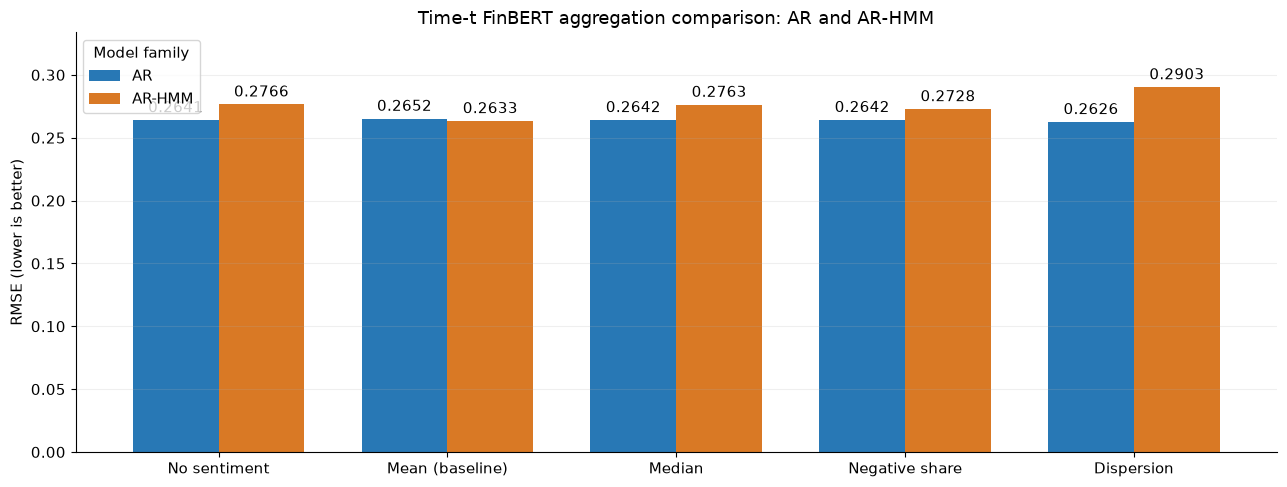

In [14]:
aggregation_names = {
    'Inflation only (lag 1)': 'No sentiment',
    'Inflation + mean sentiment (baseline)': 'Mean (baseline)',
    'Inflation + median sentiment': 'Median',
    'Inflation + negative share': 'Negative share',
    'Inflation + sentiment dispersion': 'Dispersion',
    'AR-HMM inflation only (lag 1)': 'No sentiment',
    'AR-HMM + mean sentiment (baseline)': 'Mean (baseline)',
    'AR-HMM + median sentiment': 'Median',
    'AR-HMM + negative share': 'Negative share',
    'AR-HMM + sentiment dispersion': 'Dispersion',
}
ar_plot = ar_sentiment_aggregation_metrics[['model', 'rmse']].copy()
ar_plot['aggregation'] = ar_plot['model'].map(aggregation_names)
ar_plot['family'] = 'AR'
arhmm_plot = arhmm_sentiment_aggregation_metrics[['model', 'rmse']].copy()
arhmm_plot['aggregation'] = arhmm_plot['model'].map(aggregation_names)
arhmm_plot['family'] = 'AR-HMM'
aggregation_rmse = (
    pd.concat([ar_plot, arhmm_plot], ignore_index=True)
    .pivot(index='aggregation', columns='family', values='rmse')
    .reindex(['No sentiment', 'Mean (baseline)', 'Median', 'Negative share', 'Dispersion'])
)
ax = aggregation_rmse.plot.bar(
    figsize=(13, 5), color=['#2878b5', '#d97925'], width=0.75,
    ylabel='RMSE (lower is better)',
    title='Time-t FinBERT aggregation comparison: AR and AR-HMM',
)
for container in ax.containers:
    ax.bar_label(container, fmt='%.4f', padding=3)
ax.set_xlabel('')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.set_ylim(0, float(aggregation_rmse.max().max()) * 1.15)
ax.grid(axis='y', alpha=0.2)
ax.legend(title='Model family')
plt.tight_layout()
plt.show()


,model,rmse,mae,mean_error_actual_minus_forecast
0,AR(1),0.2641,0.1950,0.0535
1,AR-HMM (2 states),0.2766,0.2026,0.0654
2,AR-HMM (4 states),0.2771,0.2011,0.0894


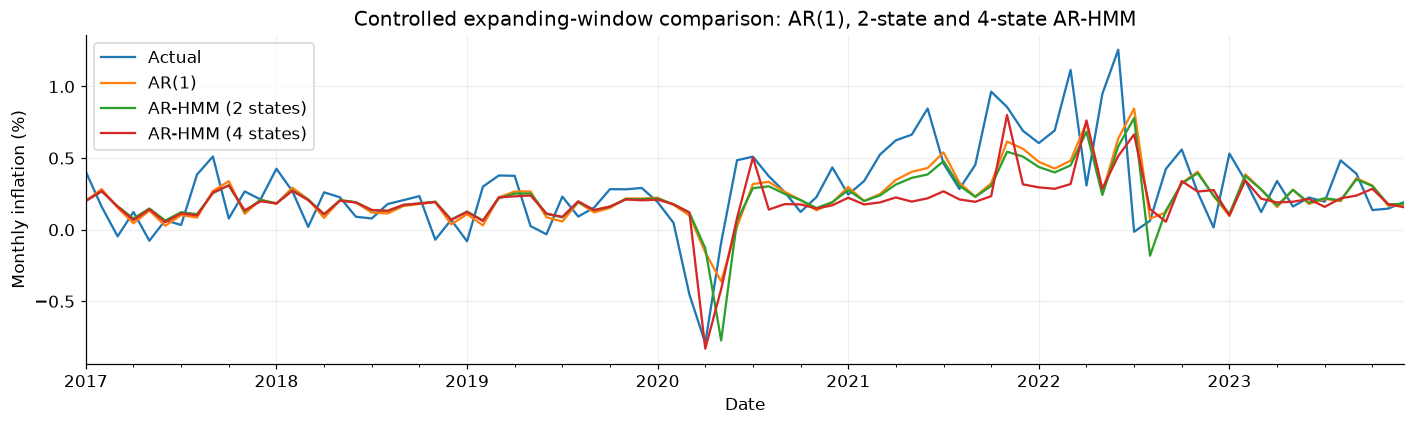

In [15]:
import sys
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from modelling.regime_experiment import run_regime_experiment, plot_predicted_regimes

N_STATES = 4
FOUR_STATE_RESULTS = RESULTS / 'arhmm_four_states'
RERUN_FOUR_STATE = False  # Set True to refit the complete controlled experiment.
if RERUN_FOUR_STATE or not (FOUR_STATE_RESULTS / 'regimes.csv').exists():
    run_regime_experiment(
        PROJECT_ROOT / 'data/processed/modelling_datasets/us_nyt_monthly_experiment.csv',
        FOUR_STATE_RESULTS, n_states=N_STATES,
    )
four_state_metrics = pd.read_csv(FOUR_STATE_RESULTS / 'metrics.csv')
four_state_forecasts = pd.read_csv(FOUR_STATE_RESULTS / 'forecasts.csv', parse_dates=['Date'])
four_state_regimes = pd.read_csv(FOUR_STATE_RESULTS / 'regimes.csv', parse_dates=['Date'])
four_state_details = json.loads((FOUR_STATE_RESULTS / 'parameters.json').read_text(encoding='utf-8'))
assert four_state_details['metadata']['n_states'] == N_STATES, 'Rerun for the selected state count'
display(four_state_metrics.round(4))
ax = four_state_forecasts.set_index('Date').plot(
    figsize=(13, 4), ylabel='Monthly inflation (%)',
    title='Controlled expanding-window comparison: AR(1), 2-state and 4-state AR-HMM',
)
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()


All monthly fits converged: True


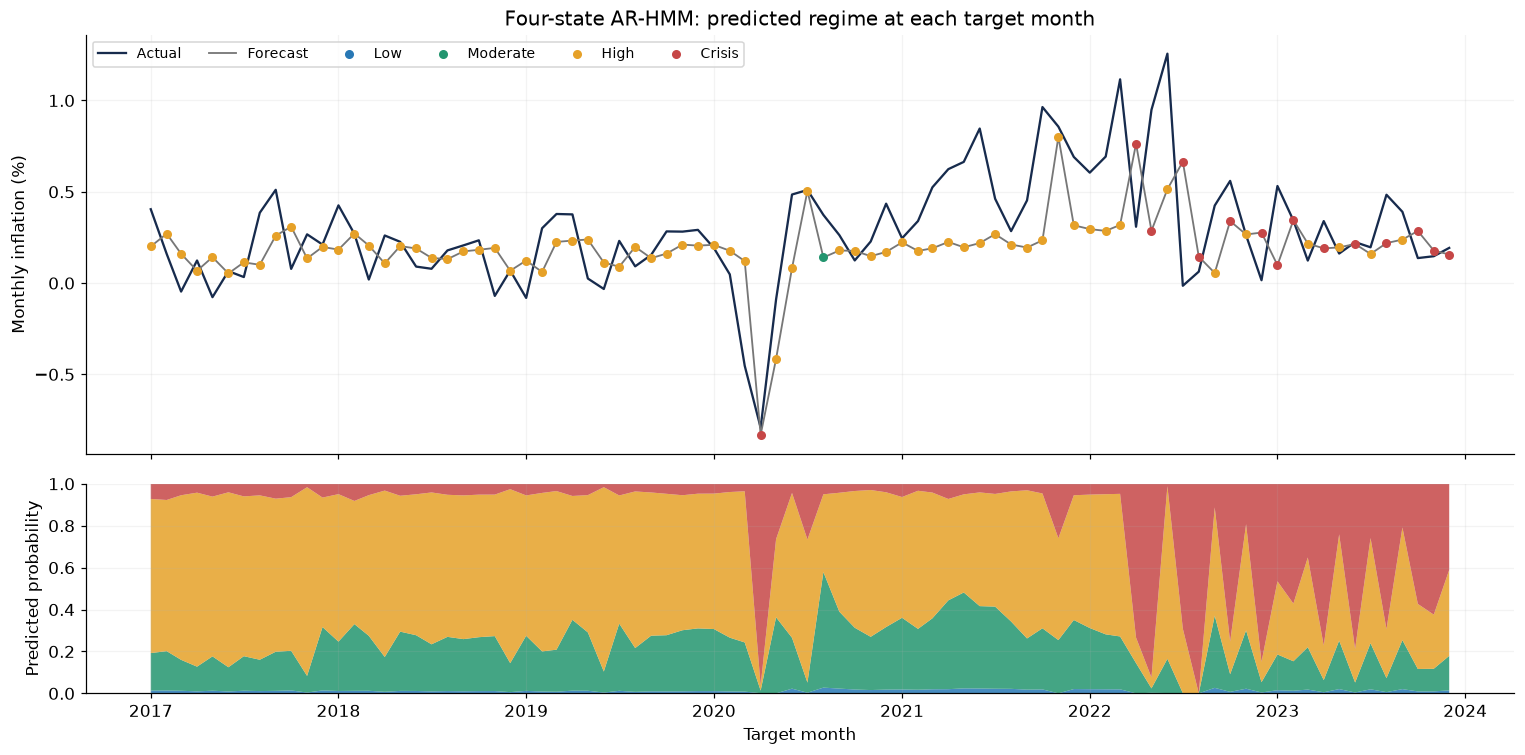

,Months with highest predicted probability
PredictedRegime,
Low,0
Moderate,1
High,68
Crisis,15


,Low,Moderate,High,Crisis
target_month,,,,
2017-01-01,-0.9856,0.0368,0.178,0.3876
2023-12-01,-1.3099,0.0656,0.170,0.2306


In [16]:
regime_labels = ['Low', 'Moderate', 'High', 'Crisis']
plot_predicted_regimes(four_state_regimes, regime_labels)
plt.show()
display(four_state_regimes['PredictedRegime'].value_counts().reindex(regime_labels, fill_value=0)
        .rename('Months with highest predicted probability').to_frame())
fit_diagnostics = pd.DataFrame(four_state_details['models']['AR-HMM (4 states)']['fits_by_origin'])
display(pd.DataFrame(
    fit_diagnostics['reference_state_levels'].tolist(), columns=regime_labels,
    index=pd.to_datetime(fit_diagnostics['target_month']),
).iloc[[0, -1]].round(4))
print('All monthly fits converged:', fit_diagnostics['converged'].all())


In [17]:
from modelling.models import ForecastResult
from modelling.evaluation import compare_results

comparison_results = {}
for bundle_name, directory in [
    ('Static saved', BASELINE), ('Expanding macro', MACRO),
    ('Expanding 2-state macro', RESULTS / 'arhmm_macro'),
    ('Expanding AR sentiment', RESULTS / 'ar_sentiment_aggregations'),
    ('Expanding 2-state sentiment', RESULTS / 'arhmm_sentiment_aggregations'),
    ('Expanding 2-state macro + sentiment', RESULTS / 'arhmm_sentiment'),
    ('Controlled state-count experiment', FOUR_STATE_RESULTS),
]:
    saved_frame = pd.read_csv(directory / 'forecasts.csv', parse_dates=['Date'])
    assert saved_frame['Date'].equals(four_state_forecasts['Date']), 'Evaluation dates differ'
    for model in saved_frame.columns.difference(['Date', 'Actual']):
        name = f'{bundle_name}: {model}'
        comparison_results[name] = ForecastResult(
            name, saved_frame[['Date', 'Actual', model]].rename(columns={model: 'Forecast'}), {},
        )
all_models_with_four_states = compare_results(comparison_results)
display(all_models_with_four_states.round(4))
all_models_with_four_states.to_csv(FOUR_STATE_RESULTS / 'all_models_comparison.csv', index=False)


,model,rmse,mae,mean_error_actual_minus_forecast
0,Expanding macro: Inflation + Oil + Unemployment,0.2617,0.1958,0.0703
1,Expanding AR sentiment: Inflation + sentiment ...,0.2626,0.1959,0.0478
2,Expanding macro: Inflation + Oil + Unemploymen...,0.2627,0.1968,0.0710
3,Expanding 2-state sentiment: AR-HMM + mean sen...,0.2633,0.1965,0.0576
4,Expanding 2-state macro + sentiment: AR-HMM in...,0.2633,0.1965,0.0576
5,Expanding AR sentiment: Inflation only (lag 1),0.2641,0.1950,0.0535
6,Expanding macro: Inflation only (lag 1),0.2641,0.1950,0.0535
7,Controlled state-count experiment: AR(1),0.2641,0.1950,0.0535
8,Expanding AR sentiment: Inflation + median sen...,0.2642,0.1940,0.0519
9,Expanding AR sentiment: Inflation + negative s...,0.2642,0.1946,0.0534


**Lag order: AR vs 2-state AR-HMM**

In [18]:
from modelling.regime_experiment import run_lag_order_experiment

LAG_ORDERS = range(1, 7)
LAG_RESULTS = RESULTS / 'arhmm_lag_orders'
RERUN_LAG_ORDERS = False
if RERUN_LAG_ORDERS or not (LAG_RESULTS / 'metrics.csv').exists():
    run_lag_order_experiment(
        PROJECT_ROOT / 'data/processed/modelling_datasets/us_nyt_monthly_experiment.csv',
        LAG_RESULTS, lag_orders=LAG_ORDERS,
    )
lag_metrics = pd.read_csv(LAG_RESULTS / 'metrics.csv')
lag_forecasts = pd.read_csv(LAG_RESULTS / 'forecasts.csv', parse_dates=['Date'])
display(lag_metrics[[
    'model', 'rmse', 'mae', 'rmse_difference_vs_ar', 'rmse_change_vs_ar_pct',
]].round(4))


,model,rmse,mae,rmse_difference_vs_ar,rmse_change_vs_ar_pct
0,AR(1),0.2645,0.1955,0.0000,0.0000
1,"AR-HMM(2 states, p=1)",0.2779,0.2033,0.0133,5.0416
2,AR(2),0.2671,0.1989,0.0000,0.0000
3,"AR-HMM(2 states, p=2)",0.3123,0.2101,0.0453,16.9505
4,AR(3),0.2658,0.1967,0.0000,0.0000
5,"AR-HMM(2 states, p=3)",0.3059,0.2112,0.0400,15.0553
6,AR(4),0.2674,0.1968,0.0000,0.0000
7,"AR-HMM(2 states, p=4)",0.2971,0.2077,0.0296,11.0758
8,AR(5),0.2724,0.2018,0.0000,0.0000
9,"AR-HMM(2 states, p=5)",0.2954,0.2070,0.0230,8.4410


Best: AR-HMM(2 states, p=1) | RMSE 0.2779 | 5.04% worse than matching AR


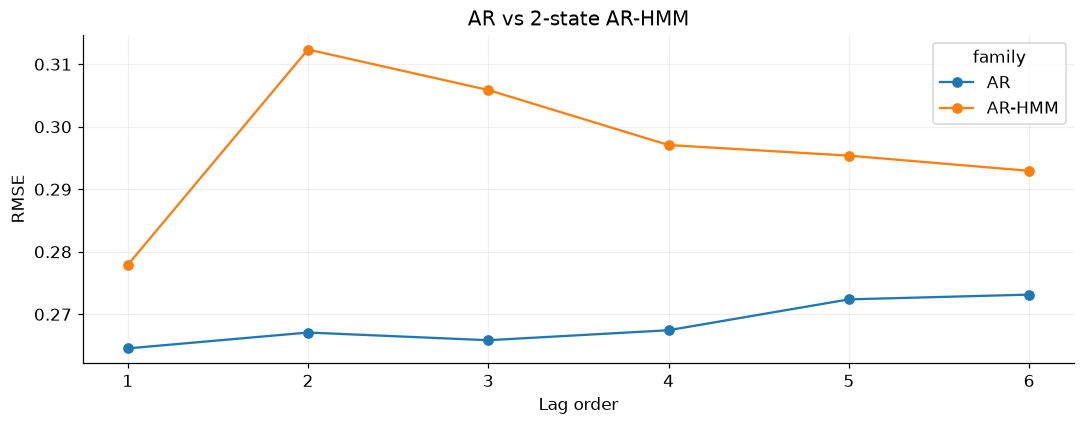

In [19]:
rmse_by_order = lag_metrics.pivot(index='lag_order', columns='family', values='rmse')
ax = rmse_by_order.plot(marker='o', figsize=(10, 4), ylabel='RMSE')
ax.set(xlabel='Lag order', title='AR vs 2-state AR-HMM')
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()
best_arhmm = lag_metrics.loc[lag_metrics['family'].eq('AR-HMM')].sort_values('rmse').iloc[0]
direction = 'worse' if best_arhmm['rmse_change_vs_ar_pct'] > 0 else 'better'
print(f"Best: {best_arhmm['model']} | RMSE {best_arhmm['rmse']:.4f} | "
      f"{abs(best_arhmm['rmse_change_vs_ar_pct']):.2f}% {direction} than matching AR")


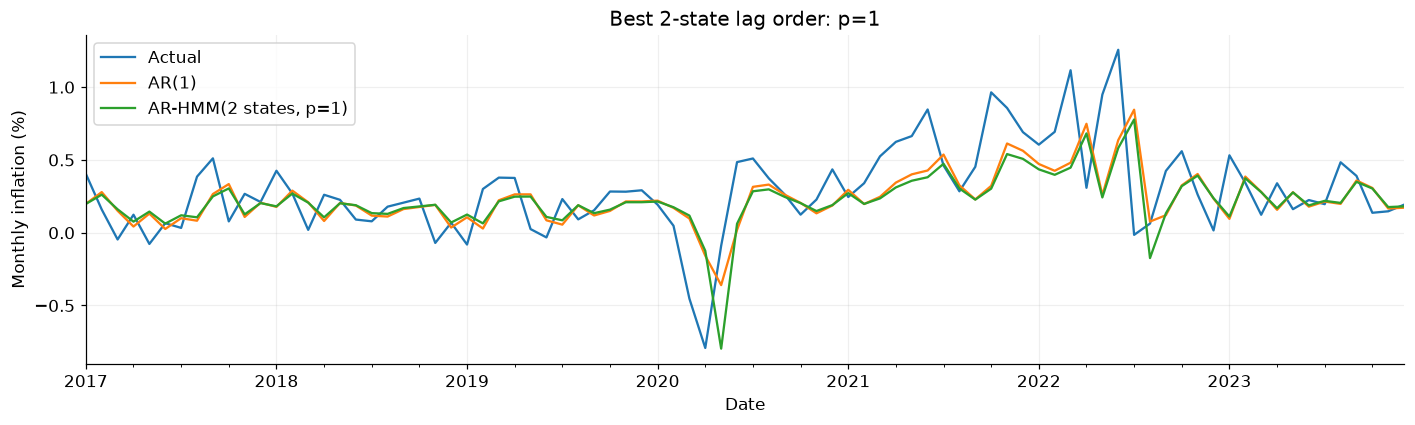

In [20]:
best_order = int(best_arhmm['lag_order'])
models = ['Actual', f'AR({best_order})', f'AR-HMM(2 states, p={best_order})']
ax = lag_forecasts.set_index('Date')[models].plot(
    figsize=(13, 4), ylabel='Monthly inflation (%)',
    title=f'Best 2-state lag order: p={best_order}',
)
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()
